# Milestone 4: frozen-policy final evaluation

The integration policy was selected using validation only and is fixed in `m4_artifacts/integration_policy.json`. This notebook evaluates **52 held-out single portraits and 39 held-out multi-person frames (175 regions)**. It also repeats the 50 validation portraits as a separate restoration check. Validation samples are not pooled into test accuracy. No training is performed, and test results are not used to tune the policy.


In [1]:
from pathlib import Path
import json
import sys
import pandas as pd
from IPython.display import display, Image

ROOT = Path.cwd().resolve()
if not (ROOT / 'src').is_dir():
    ROOT = ROOT.parent
if not (ROOT / 'src').is_dir():
    raise RuntimeError('Start Jupyter in the project root or notebooks directory')
sys.path.insert(0, str(ROOT))
from src.m4_pipeline import evaluate, verify_complete

RUN_DIR = ROOT / 'runs/m4/final_evaluation'
SOURCE_DIR = ROOT / 'data/shared_pool'
policy = json.loads((ROOT / 'm4_artifacts/integration_policy.json').read_text(encoding='utf-8'))
print('Policy:', policy['policy_id'])
print('Post-NMS IoU:', policy['post_nms_iou'])
print('Classifier conflict threshold:', policy['classifier_conflict_threshold'])
print('Output:', RUN_DIR)


Policy: m4_validation_frozen_20261013
Post-NMS IoU: 0.7
Classifier conflict threshold: 0.9
Output: /home/zhang.jiaso/ondemand/data/sys/dashboard/batch_connect/sys/jupyterlab-ml-courses/ie7615-project1/runs/m4/final_evaluation


## Execute once, reuse completed results

Use a fresh kernel after shutting down previous training kernels. PyTorch and TensorFlow run in separate subprocesses. Before test inference, the fixed policy must reproduce its recorded validation counts. The evaluation function verifies and reuses a completed result directory when Run All is clicked again. An incomplete directory is preserved and requires diagnosis.


In [2]:
evaluate(source=SOURCE_DIR, output=RUN_DIR, device='0', batch_size=8)


images/test/test_0000.jpg: 3 YOLO boxes -> 2 after post-NMS
images/test/test_0001.jpg: 4 YOLO boxes -> 3 after post-NMS
images/test/test_0002.jpg: 4 YOLO boxes -> 4 after post-NMS
images/test/test_0003.jpg: 5 YOLO boxes -> 4 after post-NMS
images/test/test_0004.jpg: 10 YOLO boxes -> 9 after post-NMS
images/test/test_0005.jpg: 1 YOLO boxes -> 1 after post-NMS
images/test/test_0006.jpg: 3 YOLO boxes -> 3 after post-NMS
images/test/test_0007.jpg: 4 YOLO boxes -> 4 after post-NMS
images/test/test_0008.jpg: 6 YOLO boxes -> 5 after post-NMS
images/test/test_0009.jpg: 11 YOLO boxes -> 9 after post-NMS
images/test/test_0010.jpg: 2 YOLO boxes -> 2 after post-NMS
images/test/test_0011.jpg: 4 YOLO boxes -> 3 after post-NMS
images/test/test_0012.jpg: 5 YOLO boxes -> 4 after post-NMS
images/test/test_0013.jpg: 6 YOLO boxes -> 5 after post-NMS
images/test/test_0014.jpg: 10 YOLO boxes -> 9 after post-NMS
images/test/test_0015.jpg: 2 YOLO boxes -> 2 after post-NMS
images/test/test_0016.jpg: 3 YOLO box

PosixPath('/home/zhang.jiaso/ondemand/data/sys/dashboard/batch_connect/sys/jupyterlab-ml-courses/ie7615-project1/runs/m4/final_evaluation')

## Final metrics

Single `test` accuracy is separate from the repeated `val` accuracy. Multi-person scores use one-to-one class-agnostic matching at IoU >= 0.5. Identity precision, recall, and F1 include missed and extra detections and identity errors. These are fixed-threshold micro metrics, **not mAP**. The original M3 mAP and M1 six-class accuracy remain separate historical results.

The saved test run obtains 46/52 single portraits correct (88.46%). The validation-selected integrated rule obtains identity F1 87.28%; the classifier-only identity decision on the same retained YOLO boxes obtains 89.60%. Both are reported below, while the preselected integrated rule remains the primary result. The stronger test ablation is not used to change the rule after evaluation.


In [3]:
verify_complete(RUN_DIR)
summary = json.loads((RUN_DIR / 'summary.json').read_text(encoding='utf-8'))
print('Validation policy replay:', json.loads((RUN_DIR / 'validation_policy_replay.json').read_text(encoding='utf-8')))
display(pd.DataFrame(summary['single']).T)
display(pd.DataFrame(summary['multi_test']['identity']).T)
display(pd.DataFrame(summary['multi_test']['localization']).T)
print('Gallery counts:', summary['gallery_counts'])
print('Cold run seconds, including subprocess startup, I/O and rendering:', summary['cold_run_seconds_including_workers_io_and_rendering'])
per_identity = pd.read_csv(RUN_DIR / 'multi_per_identity.csv', dtype={'identity': str})
display(per_identity)
singles = pd.read_csv(RUN_DIR / 'single_predictions.csv', dtype={'true_identity': str, 'predicted_identity': str})
display(singles.loc[~singles['correct']])


Validation policy replay: {'passed': True, 'counts': {'images': 39, 'ground_truth': 175, 'predictions': 174, 'localized': 173, 'extra': 1, 'missed': 2, 'final_correct': 161, 'final_all_correct_images': 28}, 'identity': {'tp': 161, 'fp': 13, 'fn': 14, 'precision': 0.9252873563218391, 'recall': 0.92, 'f1': 0.9226361031518625, 'accuracy_given_localized': 0.930635838150289}}


,images,correct,accuracy
val,50.0,43.0,0.860000
test,52.0,46.0,0.884615


,tp,fp,fn,precision,recall,f1,accuracy_given_localized,all_correct_images
raw_yolo,122.0,72.0,53.0,0.628866,0.697143,0.661247,0.713450,6.0
yolo_after_post_nms,122.0,49.0,53.0,0.713450,0.697143,0.705202,0.713450,7.0
classifier_after_post_nms,155.0,16.0,20.0,0.906433,0.885714,0.895954,0.906433,24.0
integrated,151.0,20.0,24.0,0.883041,0.862857,0.872832,0.883041,21.0


,tp,fp,fn,precision,recall,f1
raw_yolo,171.0,23.0,4.0,0.881443,0.977143,0.926829
yolo_after_post_nms,171.0,0.0,4.0,1.000000,0.977143,0.988439
classifier_after_post_nms,171.0,0.0,4.0,1.000000,0.977143,0.988439
integrated,171.0,0.0,4.0,1.000000,0.977143,0.988439


Gallery counts: {'single_correct': 20, 'single_errors': 5, 'multi': 10}
Cold run seconds, including subprocess startup, I/O and rendering: 94.97598827630281


,method,identity,tp,fp,fn,precision,recall,f1
0,integrated,3,11,0,3,1.000000,0.785714,0.880000
1,integrated,7,13,1,1,0.928571,0.928571,0.928571
2,integrated,797,8,0,5,1.000000,0.615385,0.761905
3,integrated,1212,14,0,0,1.000000,1.000000,1.000000
4,integrated,2336,12,0,1,1.000000,0.923077,0.960000
5,integrated,2619,14,0,0,1.000000,1.000000,1.000000
6,integrated,2970,13,10,1,0.565217,0.928571,0.702703
7,integrated,4422,6,1,7,0.857143,0.461538,0.600000
8,integrated,4428,14,0,0,1.000000,1.000000,1.000000
9,integrated,5695,13,0,0,1.000000,1.000000,1.000000


,split,image,true_identity,predicted_identity,confidence,correct
18,val,2336/175969.jpg,2336,8335,0.378196,False
26,val,2970/085698.jpg,2970,4422,0.928848,False
30,val,4422/081031.jpg,4422,7007,0.487483,False
38,val,5695/201941.jpg,5695,4428,0.499799,False
41,val,7007/150463.jpg,7007,2970,0.731801,False
43,val,8335/055177.jpg,8335,3,0.927715,False
47,val,10002/041931.jpg,10002,2970,0.885511,False
56,test,7/090356.jpg,7,7007,0.953850,False
58,test,797/164035.jpg,797,4422,0.835521,False
79,test,4422/043327.jpg,4422,2970,0.997798,False


## Results gallery

The [repository gallery](../m4_gallery/README.md) contains 20 correct test portraits covering all 13 identities, all 6 misclassified test portraits, and 10 multi-person examples. The previews below use the original evaluation gallery, which includes 5 of the 6 errors. Both galleries use the same predictions and metrics. Error notes discuss possible contributing factors; these factors were not tested separately.


,group,split,image,gallery_file,true_identity,predicted_identity,confidence,true_identity_probability
0,single_correct,test,10002/054636.jpg,single_correct/01_test_054636.jpg,10002,10002,0.989595,NaN
1,single_correct,test,10002/060686.jpg,single_correct/02_test_060686.jpg,10002,10002,0.999661,NaN
2,single_correct,test,1212/162783.jpg,single_correct/03_test_162783.jpg,1212,1212,0.999151,NaN
3,single_correct,test,1212/163499.jpg,single_correct/04_test_163499.jpg,1212,1212,0.999906,NaN
4,single_correct,test,1212/169060.jpg,single_correct/05_test_169060.jpg,1212,1212,0.998343,NaN
5,single_correct,test,1212/182418.jpg,single_correct/06_test_182418.jpg,1212,1212,0.999953,NaN
6,single_correct,test,2336/164885.jpg,single_correct/07_test_164885.jpg,2336,2336,0.999919,NaN
7,single_correct,test,2336/172736.jpg,single_correct/08_test_172736.jpg,2336,2336,1.000000,NaN
8,single_correct,test,2336/173519.jpg,single_correct/09_test_173519.jpg,2336,2336,0.996612,NaN
9,single_correct,test,2336/176926.jpg,single_correct/10_test_176926.jpg,2336,2336,0.999999,NaN


single_correct 01_test_054636.jpg


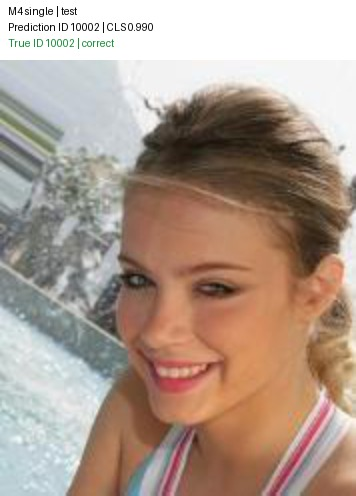

single_correct 02_test_060686.jpg


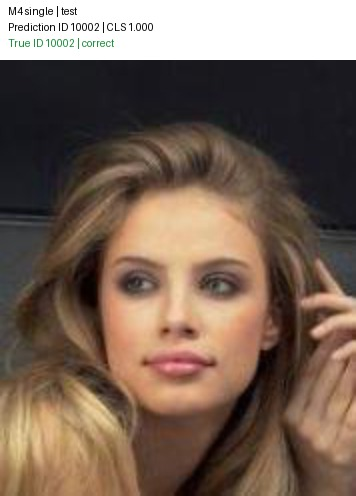

single_errors 01_test_059390.jpg


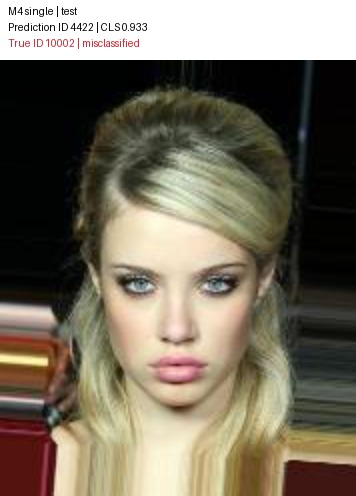

single_errors 02_test_136320.jpg


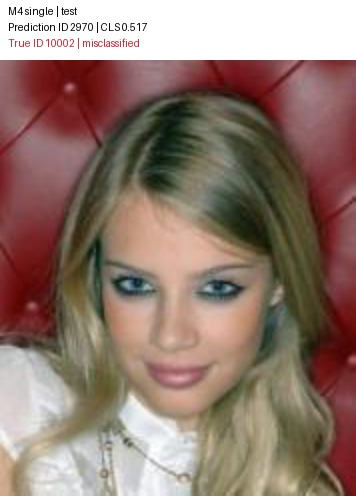

multi 01_test_test_0000.jpg


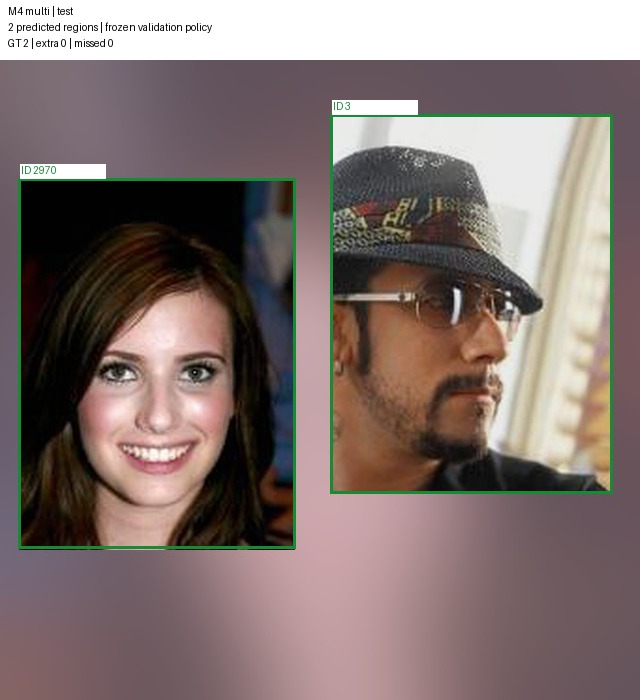

multi 02_test_test_0001.jpg


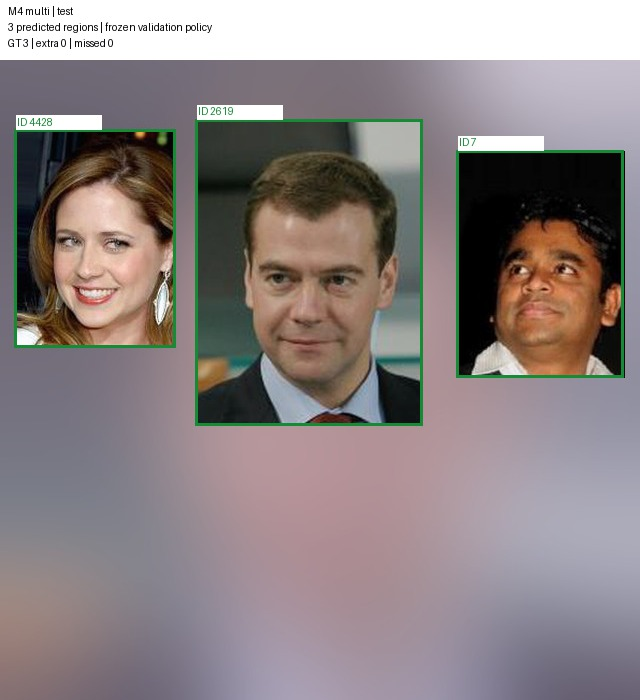

In [4]:
gallery = json.loads((RUN_DIR / 'gallery/index.json').read_text(encoding='utf-8'))
assert gallery['quantity_requirements_met']
display(pd.DataFrame(gallery['examples']))
for group in ('single_correct', 'single_errors', 'multi'):
    for path in sorted((RUN_DIR / 'gallery' / group).glob('*.jpg'))[:2]:
        print(group, path.name)
        display(Image(filename=str(path), width=500 if group == 'multi' else 320))


## New-image inference

From the server project root, the following command uses existing test images as a runnable example. For supplied new images, substitute their actual project-relative filenames.

```bash
python -m src.m4_pipeline infer \
  --single data/shared_pool/3/003206.jpg \
  --multi data/m2_detection/images/test/test_0004.jpg \
  --output "runs/m4/demo_$(date +%Y%m%d_%H%M%S_%N)" \
  --device 0
```

Either input option may be omitted. Inference loads `runs/m4/classifier13/best.weights.h5` and `m3_artifacts/best.pt`; `--output` saves predictions and annotated images, not model weights. The timestamp creates a separate result directory for each run.

The JSON records both models' multi-person predictions, the final identity and its decision rule. Single mode classifies the entire supplied portrait without estimating a face box; multi mode uses actual YOLO-predicted boxes. Unlabeled new inputs do not have measured accuracy, and an unknown person is still assigned one of the 13 known IDs. The recorded evaluation time includes subprocess startup, I/O and rendering; it is not a warm per-image latency benchmark.


## Saved evaluation artifacts

The completed run is stored in `runs/m4/final_evaluation/`. It includes `single_predictions.csv`, `multi_per_identity.csv`, `predictions.json`, `validation_policy_replay.json`, annotated images, logs and completion/integrity records. Repeating the evaluation cell verifies and reuses a completed run; an incomplete directory is preserved for diagnosis.

Repository summaries, test tables, predictions and provenance are in [m4_artifacts](../m4_artifacts/); the required curated examples and error analysis are in [m4_gallery](../m4_gallery/README.md). The original model checkpoints, validation evidence and M1-M3 experiment records remain unchanged.
